In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ntaganiraktheos/country-dataset/Country Schools.csv


**Read the dataset**

In [2]:
df = pd.read_csv("/kaggle/input/datasets/ntaganiraktheos/country-dataset/Country Schools.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (50, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


## 1.Initial analysis 

In [3]:
print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())


Data types:


,data_type
SNO,object
TOTALSCHOOLS,float64
TotalSchoolsInstalled,float64
SchoolsPending,float64
PercentageInstalled,object
InstalledLDDs,float64
InstalledTDDs,float64
FID,int64


In [4]:
print("\nNumerical summary:")
display(df.describe().T)


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
TOTALSCHOOLS,48.0,905.375000,3079.865641,93.0,271.75,422.5,637.00,21729.0
TotalSchoolsInstalled,48.0,609.541667,2078.968965,8.0,161.25,314.5,420.25,14629.0
SchoolsPending,48.0,295.833333,1009.291416,4.0,53.25,130.5,247.75,7100.0
InstalledLDDs,48.0,30150.750000,102851.947880,606.0,6289.00,14165.0,23215.00,723618.0
InstalledTDDs,48.0,1219.083333,4157.937929,16.0,322.50,629.0,840.50,29258.0
FID,50.0,25.500000,14.577380,1.0,13.25,25.5,37.75,50.0


In [5]:
print("\nCategorical summary:")
display(df.describe(include=["object"]).T)


Categorical summary:


,count,unique,top,freq
SNO,48,48,TURKANA,1
PercentageInstalled,48,48,10.34%,1


In [6]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct.round(2)
})
display(missing_summary[missing_summary["missing_count"] > 0].head(30))

,missing_count,missing_percent
SNO,2,4.0
TOTALSCHOOLS,2,4.0
TotalSchoolsInstalled,2,4.0
SchoolsPending,2,4.0
PercentageInstalled,2,4.0
InstalledLDDs,2,4.0
InstalledTDDs,2,4.0


**After initial inspection, the FID column has 2 more rows over other columns**

## 2. Data cleaning

In [7]:
df["SNO"] = df["SNO"].astype("string").str.strip().str.upper()

# Remove rows without region names
df = df.dropna(subset=["SNO"])

# Remove the total summary row
df = df[df["SNO"] != "TOTAL"].copy()

# Convert numerical columns to numeric data types
numeric_columns = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "InstalledLDDs",
    "InstalledTDDs"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Convert installation percentage from text to a number
df["PercentageInstalled"] = pd.to_numeric(
    df["PercentageInstalled"]
      .astype(str)
      .str.replace("%", "", regex=False),
    errors="coerce"
)
# Remove rows containing missing values in the analysis columns
required_columns = numeric_columns + ["PercentageInstalled"]
df = df.dropna(subset=required_columns)

# Remove duplicate regions, if any
df = df.drop_duplicates(subset=["SNO"])



print("Cleaned dataset shape:", df.shape)
display(df.head())
print("\nMissing values after cleaning:")
print(df.isnull().sum())
print("\nData types after cleaning:")
print(df.dtypes)


Cleaned dataset shape: (47, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5



Missing values after cleaning:
SNO                      0
TOTALSCHOOLS             0
TotalSchoolsInstalled    0
SchoolsPending           0
PercentageInstalled      0
InstalledLDDs            0
InstalledTDDs            0
FID                      0
dtype: int64

Data types after cleaning:
SNO                      string[python]
TOTALSCHOOLS                    float64
TotalSchoolsInstalled           float64
SchoolsPending                  float64
PercentageInstalled             float64
InstalledLDDs                   float64
InstalledTDDs                   float64
FID                               int64
dtype: object


## 3. Experiment 1: Anomaly detection

**3.1 objective**

Anomaly detection identifies observations that are significantly different from the general pattern of the dataset.

In this experiment, a region might be flagged because it has:
- An unusually high or low number of schools.
- An unusually high number of installed devices.
- A large number of schools still awaiting installation.
- A combination of school installation statistics that differs from those of other regions.
We will use the Isolation Forest algorithm, which identifies unusual observations by isolating them from the rest of the data.

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Select features for anomaly detection
features = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

X = df[features]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create the Isolation Forest model
model = IsolationForest(
    contamination=0.10,
    random_state=42
)

# Fit the model and predict anomalies
df["Anomaly"] = model.fit_predict(X_scaled)

# Calculate anomaly scores
df["AnomalyScore"] = model.decision_function(X_scaled)

# Convert model predictions into readable labels
df["AnomalyStatus"] = df["Anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

# Display the results
display(df[
    ["SNO", "AnomalyStatus", "AnomalyScore"]
].sort_values("AnomalyScore"))

# Display detected anomalies
anomalies = df[df["Anomaly"] == -1]

print("\nDetected anomalies:")
display(anomalies[
    ["SNO"] + features + ["AnomalyScore"]
].sort_values("AnomalyScore"))

,SNO,AnomalyStatus,AnomalyScore
3,KITUI,Anomaly,-0.170876
17,KAKAMEGA,Anomaly,-0.026129
0,TURKANA,Anomaly,-0.023068
13,MAKUENI,Anomaly,-0.021674
39,MACHAKOS,Anomaly,-0.010886
38,MARSABIT,Normal,0.007257
14,LAMU,Normal,0.008880
11,NANDI,Normal,0.019583
36,WAJIR,Normal,0.026680
30,MANDERA,Normal,0.035139



Detected anomalies:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,AnomalyScore
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,-0.170876
17,KAKAMEGA,880.0,572.0,308.0,65.00,44338.0,1144.0,-0.026129
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,-0.023068
13,MAKUENI,887.0,833.0,54.0,93.91,30973.0,1666.0,-0.021674
39,MACHAKOS,837.0,389.0,448.0,46.48,13369.0,778.0,-0.010886


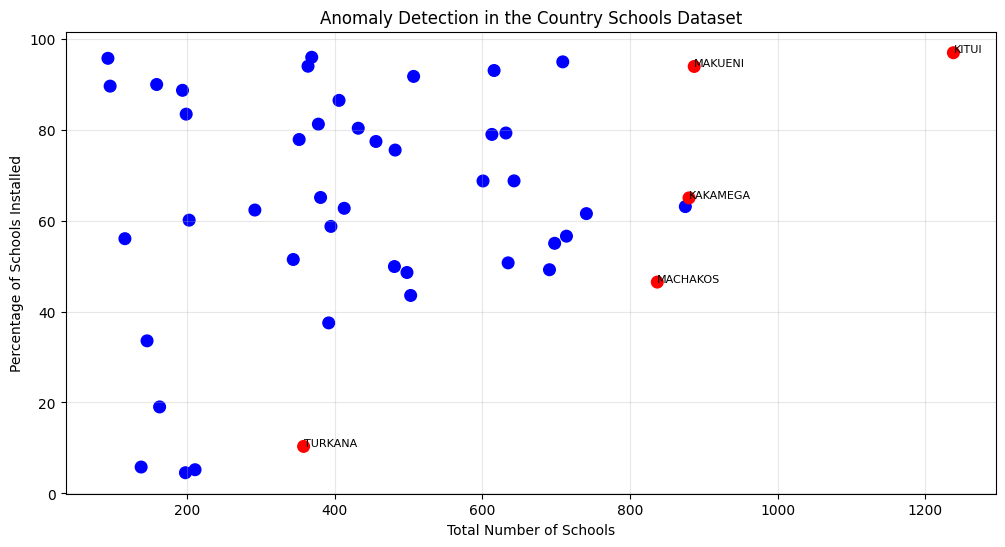

In [9]:
import matplotlib.pyplot as plt

colors = df["Anomaly"].map({
    1: "blue",
    -1: "red"
})

plt.figure(figsize=(12, 6))

plt.scatter(
    df["TOTALSCHOOLS"],
    df["PercentageInstalled"],
    c=colors,
    s=70
)

for _, row in df[df["Anomaly"] == -1].iterrows():
    plt.annotate(
        row["SNO"],
        (row["TOTALSCHOOLS"], row["PercentageInstalled"]),
        fontsize=8
    )

plt.xlabel("Total Number of Schools")
plt.ylabel("Percentage of Schools Installed")
plt.title("Anomaly Detection in the Country Schools Dataset")
plt.grid(True, alpha=0.3)
plt.show()

**3.2 Interpretation of the output**
1. Turkana

Only 37 of its 358 schools are recorded as installed, leaving 321 pending. Its installation percentage is 10.34%, making it a candidate for investigation because its installation progress is low relative to many other regions.

2. Kitui

Kitui has 1,238 schools, with 1,200 installed. Its installation percentage is 96.93%. Its combination of a large school count, high installation rate, and high device counts makes it unusual relative to other observations.

3. Makueni

Makueni has 887 schools and an installation rate of 93.91%. Its high installation rate and relatively high device counts contribute to its unusual multivariable profile.

4. Kakamega

Kakamega has 880 schools and 44,338 installed LDDs, but only 572 schools are recorded as installed. Its large LDD count relative to other regional statistics makes it worth examining.

5. Machakos

Machakos has 837 schools, but 448 remain pending, resulting in an installation rate of 46.48%. The combination of a high school count and substantial pending installations contributes to its unusual profile.
3.6 Conclusion for anomaly detection
The Isolation Forest experiment identifies regions with unusual combinations of school counts, installation progress, and device statistics. Turkana is notable for its low installation progress, while Kitui and Makueni have high installation progress. Kakamega and Machakos have distinctive combinations of school and device counts.

An anomaly does not automatically mean that a record is bad. It indicates that the further examination is recomended. The contamination=0.10 setting specifies an expected anomaly proportion of approximately 10%; it is a model setting, not a measured rate of data errors.